# 125. Valid Palindrome
**Difficulty:** 🟢 Easy · **Topic:** Two Pointers · **Pattern:** [Opposite Ends](README.md) · **LeetCode:** https://leetcode.com/problems/valid-palindrome/

## 💡 Concepts

**Core concept(s):** **Two pointers** walking inward from both ends, ignoring anything that isn't a letter or digit.

**Why it applies here:** A palindrome reads the same forwards and backwards. So the first useful character must equal the last, the second must equal the second-last, and so on — exactly what two pointers closing in from both ends check.

**Key intuition:** Compare the outermost characters, then step inward; skip spaces and punctuation.

---

### 📚 What is the Two-Pointer Technique?
Two indices that move through the string — often one from each end — so you cover it in a **single sweep** instead of nested loops.
- **Complexity:** one **O(n)** pass, **O(1)** extra space.
- **In Python:** two integer variables (e.g. `i`, `j`).

---

**Prerequisite knowledge:**
- Two-pointer scanning.
- `str.isalnum()` and `str.lower()`.

## 📝 Problem

Return `True` if the string reads the same forwards and backwards, considering only letters and digits and ignoring case.

**Example**
```
"A man, a plan, a canal: Panama" -> True
"race a car"                     -> False
```

> Two meaningfully distinct approaches: clean-then-reverse `O(n)` space, and two pointers `O(1)` space.

### Approach 1 — Clean, Then Reverse (worst on memory)

**Idea:** Build a new string of just the lowercase letters/digits, then check it equals its reverse.

**Time complexity:** `O(n)`.

**Space complexity:** `O(n)` for the cleaned copy.

In [1]:
def is_palindrome_clean(s: str) -> bool:
    # Build a cleaned copy: keep only letters/digits, all lowercased.
    cleaned = [c.lower() for c in s if c.isalnum()]
    return cleaned == cleaned[::-1]        # a palindrome reads the same reversed

### Approach 2 — Two Pointers (optimal)

**Idea:** One pointer at each end. Skip non-alphanumeric characters, compare the rest (lowercased), and move inward.

**Time complexity:** `O(n)`.

**Space complexity:** `O(1)` — no extra copy.

In [2]:
def is_palindrome_twoptr(s: str) -> bool:
    i, j = 0, len(s) - 1                   # one pointer at each end
    while i < j:                           # walk them toward the middle
        while i < j and not s[i].isalnum():
            i += 1                         # skip non-letters/digits on the left
        while i < j and not s[j].isalnum():
            j -= 1                         # skip non-letters/digits on the right
        if s[i].lower() != s[j].lower():   # mirror characters must match (ignore case)
            return False                   # mismatch -> not a palindrome
        i += 1; j -= 1                     # both matched -> step inward
    return True                            # met in the middle with no mismatch

In [3]:
# Correctness check
tests = [("A man, a plan, a canal: Panama",True), ("race a car",False), (" ",True), ("0P",False), ("aba",True), ("Taco cat",True)]
for s, exp in tests:
    a, b = is_palindrome_clean(s), is_palindrome_twoptr(s)
    print(f"{s!r:>34} -> clean={a}, twoptr={b} | expected={exp}")
    assert a == b == exp, "mismatch!"
print("\nAll tests passed")

  'A man, a plan, a canal: Panama' -> clean=True, twoptr=True | expected=True
                      'race a car' -> clean=False, twoptr=False | expected=False
                               ' ' -> clean=True, twoptr=True | expected=True
                              '0P' -> clean=False, twoptr=False | expected=False
                             'aba' -> clean=True, twoptr=True | expected=True
                        'Taco cat' -> clean=True, twoptr=True | expected=True

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. We time each approach on inputs of growing `n` and read the **doubling ratio** — how much runtime grows when `n` doubles.

| Theoretical | Ratio when `n` → `2n` |
|-------------|-----------------------|
| `O(n)`        | ≈ **2×** |
| `O(n log n)`  | ≈ **2×** (slightly more) |
| `O(n²)`       | ≈ **4×** |
| `O(n³)`       | ≈ **8×** |

Inputs are built to force the **worst case** (no early exit). Sub-millisecond rows are noisy — look at the trend.


clean  O(n) time/space
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     4000 |       0.14 |           n/a
     8000 |       0.22 |         1.60x
    16000 |       0.49 |         2.25x
    32000 |       0.92 |         1.88x

twoptr O(n) time O(1)  
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     4000 |       0.19 |           n/a
     8000 |       0.32 |         1.64x
    16000 |       0.62 |         1.98x
    32000 |       1.27 |         2.03x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


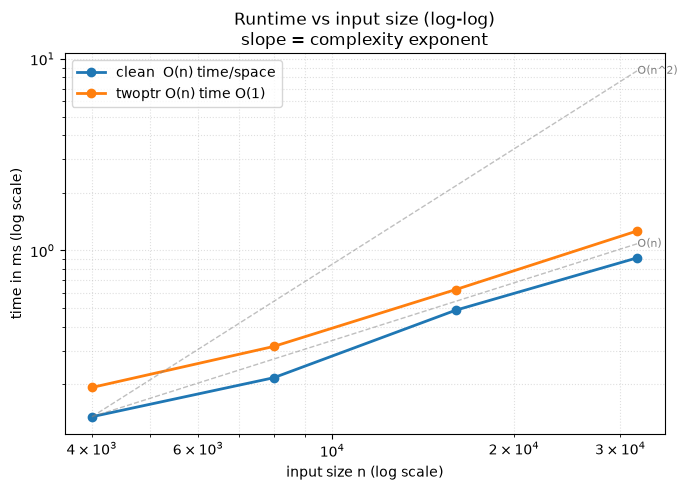

{'clean  O(n) time/space': [0.1355829881504178,
  0.21666602697223425,
  0.48741698265075684,
  0.9157500462606549],
 'twoptr O(n) time O(1)  ': [0.19275001250207424,
  0.3155419835820794,
  0.6245829863473773,
  1.2656250037252903]}

In [4]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark   # shared: prints ratio table + optional log-log plot

def make_worst_case(n):
    s = "a" * n                             # a real palindrome -> full scan, no early exit
    return (s,)

solutions = {
    "clean  O(n) time/space": is_palindrome_clean,
    "twoptr O(n) time O(1)  ": is_palindrome_twoptr,
}
sizes = [4000, 8000, 16000, 32000]

benchmark(solutions, make_worst_case, sizes, plot=True)


## 🧩 Patterns Learned

- **Pattern:** [Opposite Ends](README.md) — the template as a mirror check: compare `s[i]` with `s[j]`, skip non-alphanumerics, and step both pointers inward on a match.
- **Two pointers from both ends:** the go-to for "same forwards and backwards" and for comparing mirror positions with `O(1)` memory.
- **Filter while you scan:** skip unwanted characters in place instead of building a new string.
- **Signal:** "palindrome", "reads the same reversed", "mirror".
- **Related problems:** Valid Palindrome II, Reverse String, Two Sum II, Container With Most Water.
- **Common pitfalls:** (1) forgetting to lowercase; (2) not skipping punctuation on *both* sides; (3) letting pointers cross while skipping.